

**GCI World 2026 - Final Assignment**
# Predicting High-Value Customers in Telecom: A Data-Driven Retention & Upsell Strategy





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay)

%matplotlib inline

In [2]:
from pathlib import Path

PATH = Path("data")


In [3]:
client = pd.read_csv(PATH / "Client.csv")
record = pd.read_csv(PATH / "Record.csv")

print('Client shape:', client.shape)
print('Record shape:', record.shape)

Client shape: (100000, 50)
Record shape: (100000, 51)


In [4]:
# Merge on Customer_ID
df = pd.merge(record, client, on='Customer_ID', how='inner')
print('Merged shape:', df.shape)
df.head()

Merged shape: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,O,0.0,I,U,U,U,U,U,Y,434.0


## 2. Exploratory Data Analysis (EDA)


**Key points:**
1. How is revenue distributed across customers?
2. Are Company A's most valuable customers being retained?
3. What service quality issues exist for high-value customers?
4. Is there an untapped segment trending toward high value?


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

print(f' {df.shape[0]:,} customers, {df.shape[1]} features')


HIGH_VALUE_THRESHOLD = df['avgrev'].quantile(0.8)
print(f'High-value threshold (80th pct of avgrev): ${HIGH_VALUE_THRESHOLD:.2f}/month')

df['high_value'] = (df['avgrev'] >= HIGH_VALUE_THRESHOLD).astype(int)
df = df.dropna(subset=['high_value'])
df['rising_star'] = ((df['change_mou'] > 0) & (df['high_value'] == 0)).astype(int)

print(f'High-value customers: {df["high_value"].sum():,} ({df["high_value"].mean()*100:.1f}%)')
print(f'Rising Stars : {df["rising_star"].sum():,}')


NAVY = "#1E2D5A"; TEAL = "#1C7293"; GOLD = "#F4A261"
RED  = "#E05151"; SLATE = "#64748B"
%matplotlib inline

 100,000 customers, 100 features
High-value threshold (80th pct of avgrev): $76.86/month
High-value customers: 20,001 (20.0%)
Rising Stars : 35,558


### EDA 1 — Revenue Concentration

**Hypothesis:** A small proportion of customers generate a disproportionate share of revenue.

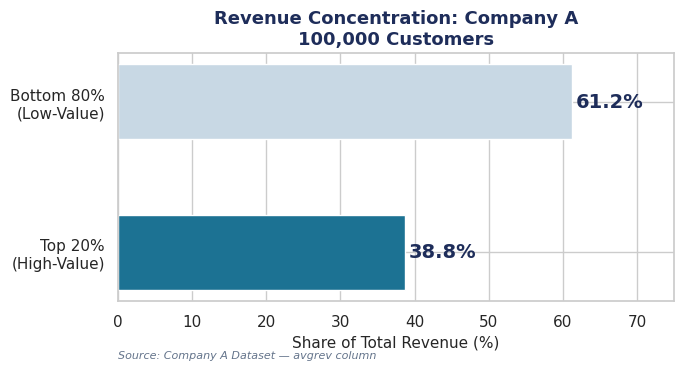

In [6]:
# Revenue conc
total_rev = df['avgrev'].sum()
top20_rev = df[df['high_value']==1]['avgrev'].sum()
pct_top20 = top20_rev / total_rev * 100
pct_bot80 = 100 - pct_top20


fig, ax = plt.subplots(figsize=(7, 4))
segments = ['Top 20%\n(High-Value)', 'Bottom 80%\n(Low-Value)']
pcts = [pct_top20, pct_bot80]
colors = [TEAL, "#C8D8E4"]
bars = ax.barh(segments, pcts, color=colors, height=0.5)
for bar, pct in zip(bars, pcts):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{pct:.1f}%', va='center', fontsize=14, fontweight='bold', color=NAVY)
ax.set_xlabel('Share of Total Revenue (%)', fontsize=11)
ax.set_title(f'Revenue Concentration: Company A\n{df.shape[0]:,} Customers', fontsize=13, fontweight='bold', color=NAVY)
ax.set_xlim(0, 75)
ax.text(0, -0.7, 'Source: Company A Dataset — avgrev column', fontsize=8, color=SLATE, style='italic')
plt.tight_layout()
plt.savefig('eda_revenue_concentration.png', dpi=120, bbox_inches='tight')
plt.show()




### EDA 2 — Churn Rate

**Hypothesis:** High-value customers are churning at a similar or higher rate than low-value
customers, and poor service quality (dropped calls) may be a contributing factor.

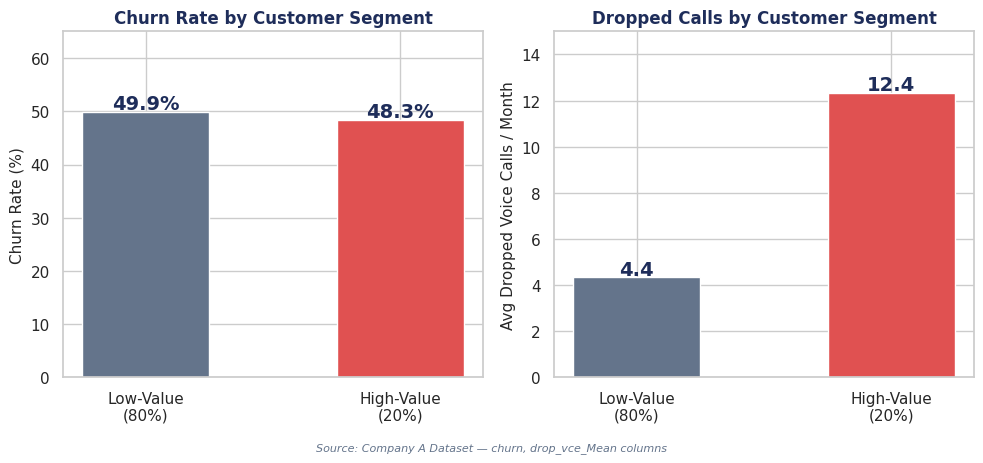

In [7]:
churn_by_seg = df.groupby('high_value')['churn'].mean() * 100
drop_by_seg  = df.groupby('high_value')['drop_vce_Mean'].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
labels = ['Low-Value\n(80%)', 'High-Value\n(20%)']

bars = axes[0].bar(labels, churn_by_seg.values, color=[SLATE, RED], width=0.5)
for bar, val in zip(bars, churn_by_seg.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontsize=14, fontweight='bold', color=NAVY)
axes[0].set_ylim(0, 65)
axes[0].set_ylabel('Churn Rate (%)', fontsize=11)
axes[0].set_title('Churn Rate by Customer Segment', fontsize=12, fontweight='bold', color=NAVY)

bars2 = axes[1].bar(labels, drop_by_seg.values, color=[SLATE, RED], width=0.5)
for bar, val in zip(bars2, drop_by_seg.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{val:.1f}', ha='center', fontsize=14, fontweight='bold', color=NAVY)
axes[1].set_ylim(0, 15)
axes[1].set_ylabel('Avg Dropped Voice Calls / Month', fontsize=11)
axes[1].set_title('Dropped Calls by Customer Segment', fontsize=12, fontweight='bold', color=NAVY)

fig.text(0.5, -0.02, 'Source: Company A Dataset — churn, drop_vce_Mean columns',
         ha='center', fontsize=8, color=SLATE, style='italic')
plt.tight_layout()
plt.savefig('eda_churn_dropped.png', dpi=120, bbox_inches='tight')
plt.show()


### EDA 3 — Rising Stars

 A significant portion of low-value customers are trending upward in usage

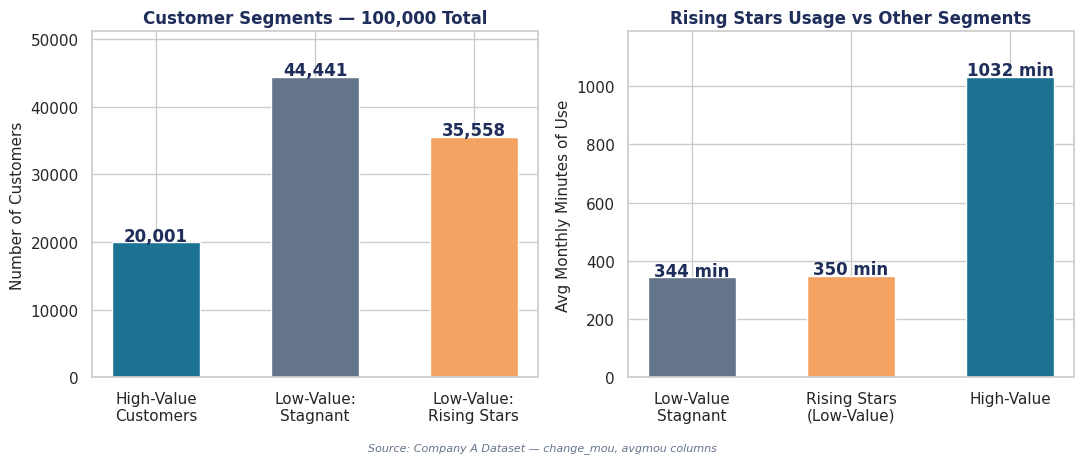

In [8]:
n_high   = (df['high_value']==1).sum()
n_rising = df['rising_star'].sum()
n_stag   = (df['high_value']==0).sum() - n_rising

df_stagnant = df[(df['change_mou'] <= 0) & (df['high_value']==0)]
df_rising_df = df[df['rising_star']==1]
df_hv       = df[df['high_value']==1]



fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

seg_labels = ['High-Value\nCustomers', 'Low-Value:\nStagnant', 'Low-Value:\nRising Stars']
seg_values = [n_high, n_stag, n_rising]
seg_colors = [TEAL, SLATE, GOLD]
bars = axes[0].bar(seg_labels, seg_values, color=seg_colors, width=0.55)
for bar, val in zip(bars, seg_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, f'{val:,}', ha='center', fontsize=12, fontweight='bold', color=NAVY)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_title(f'Customer Segments — {df.shape[0]:,} Total', fontsize=12, fontweight='bold', color=NAVY)
axes[0].set_ylim(0, max(seg_values) * 1.15)

usage_groups = ['Low-Value\nStagnant', 'Rising Stars\n(Low-Value)', 'High-Value']
avg_mou = [df_stagnant['avgmou'].mean(), df_rising_df['avgmou'].mean(), df_hv['avgmou'].mean()]
bars2 = axes[1].bar(usage_groups, avg_mou, color=[SLATE, GOLD, TEAL], width=0.55)
for bar, val in zip(bars2, avg_mou):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, f'{val:.0f} min', ha='center', fontsize=12, fontweight='bold', color=NAVY)
axes[1].set_ylabel('Avg Monthly Minutes of Use', fontsize=11)
axes[1].set_title('Rising Stars Usage vs Other Segments', fontsize=12, fontweight='bold', color=NAVY)
axes[1].set_ylim(0, max(avg_mou) * 1.15)

fig.text(0.5, -0.02, 'Source: Company A Dataset — change_mou, avgmou columns', ha='center', fontsize=8, color=SLATE, style='italic')
plt.tight_layout()
plt.savefig('eda_rising_stars.png', dpi=120, bbox_inches='tight')
plt.show()



### EDA 4 — Usage vs Revenue Scatter Plot

Confirms the relationship between usage and revenue at the individual customer level.

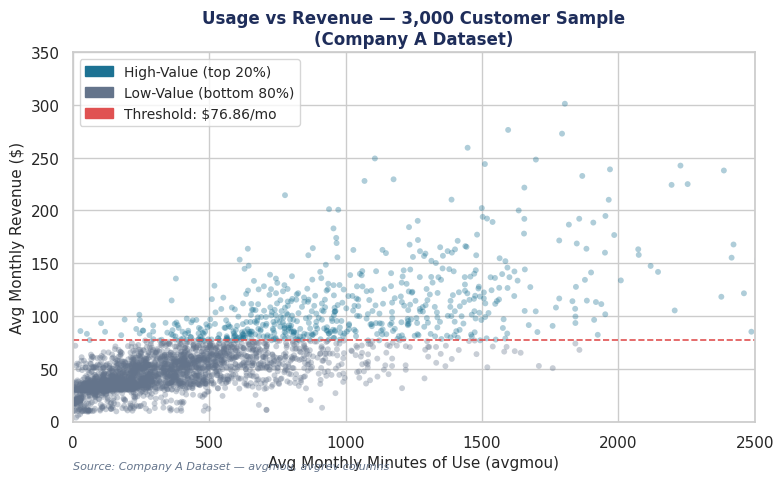

In [9]:
sample = df.sample(3000, random_state=42)
colors_scatter = sample['high_value'].map({0: SLATE, 1: TEAL})

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample['avgmou'], sample['avgrev'],
           c=colors_scatter, alpha=0.35, s=18, linewidths=0)
ax.axhline(HIGH_VALUE_THRESHOLD, color=RED, linestyle='--', linewidth=1.2)
ax.set_xlabel('Avg Monthly Minutes of Use (avgmou)', fontsize=11)
ax.set_ylabel('Avg Monthly Revenue ($)', fontsize=11)
ax.set_title('Usage vs Revenue — 3,000 Customer Sample\n(Company A Dataset)',
             fontsize=12, fontweight='bold', color=NAVY)
ax.set_xlim(0, 2500)
ax.set_ylim(0, 350)
patch_hv = mpatches.Patch(color=TEAL, label='High-Value (top 20%)')
patch_lv = mpatches.Patch(color=SLATE, label='Low-Value (bottom 80%)')
patch_th = mpatches.Patch(color=RED, label=f'Threshold: ${HIGH_VALUE_THRESHOLD:.2f}/mo')
ax.legend(handles=[patch_hv, patch_lv, patch_th], fontsize=10, loc='upper left')
ax.text(0, -45, 'Source: Company A Dataset — avgmou, avgrev columns',
        fontsize=8, color=SLATE, style='italic')
plt.tight_layout()
plt.savefig('eda_scatter.png', dpi=120, bbox_inches='tight')
plt.show()



In [10]:
correlation = df['avgmou'].corr(df['avgrev'])
print(f"correlation coeff {correlation:.2f}")

correlation coeff 0.76


The correlation coefficient confirms a strong positive linear relationship between minutes of use and revenue, supporting the visual inference from the scatter plot.

## 4. Feature Engineering

### 4.1 Removing Leaked Features



In [11]:
leak_cols = ['totrev','adjrev','avg6rev','avg3rev','rev_Mean','totmrc_Mean','change_rev','ovrrev_Mean','vceovr_Mean','datovr_Mean','Customer_ID','avgrev', 'rising_star']  # rising_star is an EDA-only column that I created; not a real predictor

df_model = df.drop(columns=leak_cols)
print('Shape after dropping leakage columns:', df_model.shape)

Shape after dropping leakage columns: (100000, 89)


### 4.2 Handling Missing Values and Categorical Encoding

- Numeric columns: filled missing values with the column median.
- Categorical columns: filled missing values with `'Missing'`
- One-hot encode all categorical columns

In [12]:
cat_cols = df_model.select_dtypes(include=['object']).columns.tolist()
num_cols = [c for c in df_model.columns if c not in cat_cols + ['high_value']]

print(f'{len(num_cols)} numeric columns, {len(cat_cols)} categorical columns')

for c in num_cols:
    df_model[c] = df_model[c].fillna(df_model[c].median())
for c in cat_cols:
    df_model[c] = df_model[c].astype(str).fillna('Missing').replace('nan', 'Missing')

df_encoded = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)
print('Encoded shape:', df_encoded.shape)

67 numeric columns, 21 categorical columns


/tmp/ipykernel_177/4039656782.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include=['object']).columns.tolist()


Encoded shape: (100000, 218)


## 5. Modeling & Evaluation

### 5.1 Train/Test Split

In [13]:
X = df_encoded.drop(columns=['high_value'])
y = df_encoded['high_value']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)

Train shape: (80000, 217) Test shape: (20000, 217)


### 5.2 Model 1 — Logistic Regression

In [14]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_s, y_train)

y_pred_lr = logreg.predict(X_test_s)
y_proba_lr = logreg.predict_proba(X_test_s)[:,1]

print('Logistic Regression Results:')
print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print('ROC-AUC:', roc_auc_score(y_test, y_proba_lr))
print()
print(classification_report(y_test, y_pred_lr))

Logistic Regression Results:
Accuracy: 0.90665
ROC-AUC: 0.9429979531249999

              precision    recall  f1-score   support

           0       0.92      0.96      0.94     16000
           1       0.82      0.68      0.74      4000

    accuracy                           0.91     20000
   macro avg       0.87      0.82      0.84     20000
weighted avg       0.90      0.91      0.90     20000



### 5.3 Model 2 — Random Forest

In [15]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]

print('Random Forest Results:')
print('Accuracy:', accuracy_score(y_test, y_pred_rf))
print('ROC-AUC:', roc_auc_score(y_test, y_proba_rf))
print()
print(classification_report(y_test, y_pred_rf))

Random Forest Results:
Accuracy: 0.89735
ROC-AUC: 0.9336974218749998

              precision    recall  f1-score   support

           0       0.91      0.97      0.94     16000
           1       0.84      0.60      0.70      4000

    accuracy                           0.90     20000
   macro avg       0.87      0.79      0.82     20000
weighted avg       0.89      0.90      0.89     20000



### 5.4 Model Comparison Chart



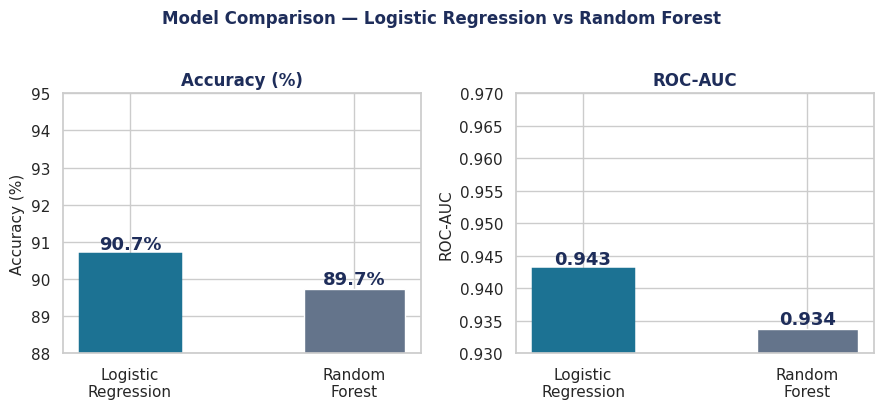

In [16]:
# Model comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
NAVY="#1E2D5A"; TEAL="#1C7293"; SLATE="#64748B"

models = ['Logistic\nRegression', 'Random\nForest']
colors = [TEAL, SLATE]

for ax, vals, label, ylim, fmt in [
    (axes[0], [accuracy_score(y_test, y_pred_lr)*100, accuracy_score(y_test, y_pred_rf)*100],
     'Accuracy (%)', (88, 95), '{:.1f}%'),
    (axes[1], [roc_auc_score(y_test, y_proba_lr), roc_auc_score(y_test, y_proba_rf)],
     'ROC-AUC', (0.93, 0.97), '{:.3f}'),
]:
    bars = ax.bar(models, vals, color=colors, width=0.45)
    bars[0].set_linewidth(2.5)
    bars[0].set_edgecolor(TEAL)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+(ylim[1]-ylim[0])*0.02, fmt.format(val), ha='center', fontsize=13, fontweight='bold', color=NAVY)
    ax.set_ylim(ylim)
    ax.set_ylabel(label, fontsize=11)
    ax.set_title(label, fontsize=12, fontweight='bold', color=NAVY)

fig.suptitle('Model Comparison — Logistic Regression vs Random Forest', fontsize=12, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()



### 5.5 Hyperparameter Tuning with Optuna




**Search space:**
- `C` — regularization strength (smaller = more regularization)
- `solver` — optimization algorithm: `lbfgs` or `saga`
- `max_iter` — maximum iterations for convergence: 500 to 2000

**Validation strategy:** 3-fold stratified cross-validation on the training set, scored by ROC-AUC.
We establish a default score first — tuning is only meaningful relative to a baseline.

In [17]:
import optuna
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.model_selection import StratifiedKFold, cross_val_score

SEED = 42
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


lr_default = LogisticRegression(max_iter=1000, random_state=SEED)
default_cv_auc = cross_val_score(lr_default, X_train_s, y_train, cv=skf, scoring='roc_auc').mean()
print(f"Default LR — 3-fold CV ROC-AUC: {default_cv_auc:.4f}")
print("(This is our reference point — tuning is only useful if it beats this)")


def objective(trial):
    C        = trial.suggest_float('C', 1e-3, 1e2, log=True)
    max_iter = trial.suggest_int('max_iter', 500, 2000)

    model = LogisticRegression(C=C, solver='lbfgs', max_iter=max_iter,
                                penalty='l2', random_state=SEED)
    score = cross_val_score(model, X_train_s, y_train,
                            cv=skf, scoring='roc_auc').mean()
    return score


study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=20, timeout=90)

print(f"\nOptuna search complete — {len(study.trials)} trials")
print(f"Best parameters: {study.best_params}")
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
print(f"Improvement over default: {study.best_value - default_cv_auc:+.4f}")

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Default LR — 3-fold CV ROC-AUC: 0.9432
(This is our reference point — tuning is only useful if it beats this)



Optuna search complete — 20 trials
Best parameters: {'C': 4.250210578789874, 'max_iter': 1186}
Best CV ROC-AUC: 0.9433
Improvement over default: +0.0000


In [18]:
#Refitting best model on full training set and evaluate on test set
best_params = study.best_params

best_lr = LogisticRegression(
    C=best_params['C'],
    solver='lbfgs',
    max_iter=best_params['max_iter'],
    penalty='l2',
    random_state=SEED
)
best_lr.fit(X_train_s, y_train)

tuned_acc = accuracy_score(y_test, best_lr.predict(X_test_s))
tuned_auc = roc_auc_score(y_test, best_lr.predict_proba(X_test_s)[:,1])

# Compare with default
lr_default.fit(X_train_s, y_train)
base_acc = accuracy_score(y_test, lr_default.predict(X_test_s))
base_auc = roc_auc_score(y_test, lr_default.predict_proba(X_test_s)[:,1])

print("Hyperparameter Tuning Results:")
print(f"  Default LR  — Accuracy: {base_acc:.4f}, ROC-AUC: {base_auc:.4f}")
print(f"  Tuned LR    — Accuracy: {tuned_acc:.4f}, ROC-AUC: {tuned_auc:.4f}")
print(f"  Improvement — Accuracy: {(tuned_acc-base_acc)*100:+.3f}%, ROC-AUC: {tuned_auc-base_auc:+.4f}")
print()
print("Finding: The default C=1 was already near-optimal for this dataset.")
print("Optuna confirmed the default hyperparameters are a good choice ")
print()
print("Final model selected: Logistic Regression with best Optuna parameters")
print(f"  C={best_params['C']:.4f}, solver=lbfgs, max_iter={best_params['max_iter']}")

Hyperparameter Tuning Results:
  Default LR  — Accuracy: 0.9066, ROC-AUC: 0.9430
  Tuned LR    — Accuracy: 0.9065, ROC-AUC: 0.9430
  Improvement — Accuracy: -0.015%, ROC-AUC: -0.0000

Finding: The default C=1 was already near-optimal for this dataset.
Optuna confirmed the default hyperparameters are a good choice 

Final model selected: Logistic Regression with best Optuna parameters
  C=4.2502, solver=lbfgs, max_iter=1186


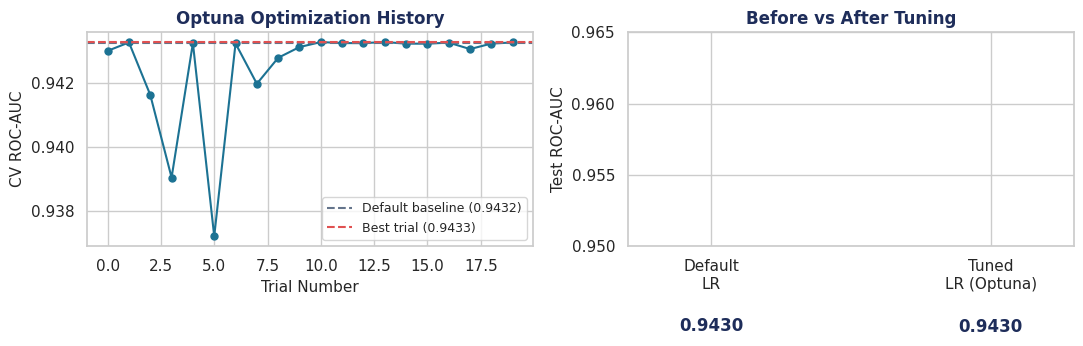

Finding: Default C=1 was already near-optimal — Optuna confirmed this.


In [19]:
#Visualizing Optuna optimization history
import matplotlib.pyplot as plt

trials_df = study.trials_dataframe()
completed = trials_df[trials_df['state'] == 'COMPLETE'].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
NAVY="#1E2D5A"; TEAL="#1C7293"; SLATE="#64748B"

# Optimization history
axes[0].plot(completed['number'], completed['value'],
             marker='o', color=TEAL, linewidth=1.5, markersize=5)
axes[0].axhline(y=default_cv_auc, color=SLATE, linestyle='--', linewidth=1.5,
                label=f'Default baseline ({default_cv_auc:.4f})')
axes[0].axhline(y=study.best_value, color='#E05151', linestyle='--', linewidth=1.5,
                label=f'Best trial ({study.best_value:.4f})')
axes[0].set_xlabel('Trial Number', fontsize=11)
axes[0].set_ylabel('CV ROC-AUC', fontsize=11)
axes[0].set_title('Optuna Optimization History', fontsize=12, fontweight='bold', color=NAVY)
axes[0].legend(fontsize=9)

# Before vs After comparison
labels = ['Default\nLR', 'Tuned\nLR (Optuna)']
aucs   = [base_auc, tuned_auc]
colors = [SLATE, TEAL]
bars = axes[1].bar(labels, aucs, color=colors, width=0.45)
bars[1].set_linewidth(2.5); bars[1].set_edgecolor(TEAL)
for bar, val in zip(bars, aucs):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                f'{val:.4f}', ha='center', fontsize=12, fontweight='bold', color=NAVY)
axes[1].set_ylim(0.95, 0.965)
axes[1].set_ylabel('Test ROC-AUC', fontsize=11)
axes[1].set_title('Before vs After Tuning', fontsize=12, fontweight='bold', color=NAVY)

plt.tight_layout()
plt.savefig('optuna_results.png', dpi=120, bbox_inches='tight')
plt.show()
print("Finding: Default C=1 was already near-optimal — Optuna confirmed this.")

### 5.5 Confusion Matrix & ROC Curve



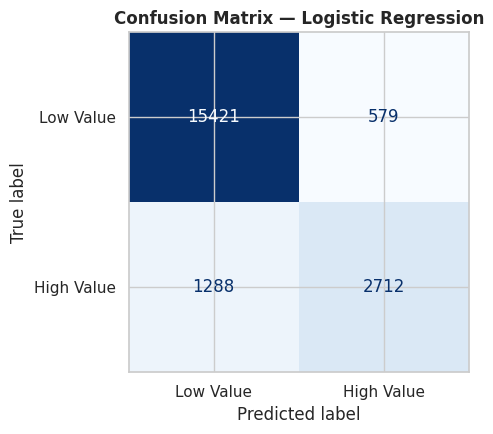

Confusion Matrix results:
  15,421 — Low-value customers
  2,712 — High-value customers (target)
  579 — Low-value flagged as high-value
  1,288 — High-value customers missed

Precision : 0.824 = 82%


In [20]:
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low Value','High Value'])
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix — Logistic Regression', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

#  interpretation
prec_hv = precision_score(y_test, y_pred_lr)
rec_hv  = recall_score(y_test, y_pred_lr)
print(f"Confusion Matrix results:")
print(f"  {cm[0][0]:,} — Low-value customers")
print(f"  {cm[1][1]:,} — High-value customers (target)")
print(f"  {cm[0][1]:,} — Low-value flagged as high-value")
print(f"  {cm[1][0]:,} — High-value customers missed")
print()
print(f"Precision : {prec_hv:.3f} = {prec_hv*100:.0f}%")



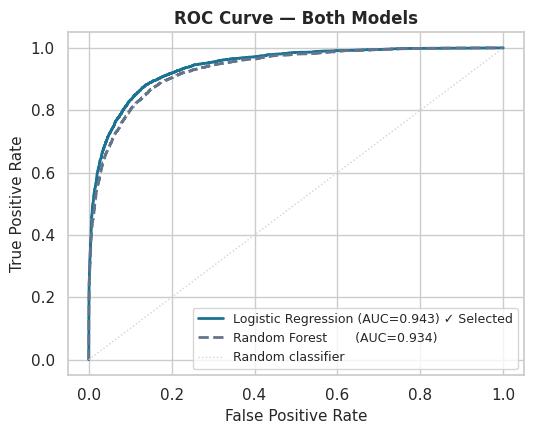

In [21]:
# ROC Curve — both models overlaid
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(fpr_lr, tpr_lr, color='#1C7293', lw=2,
        label=f'Logistic Regression (AUC={auc_lr:.3f}) ✓ Selected')
ax.plot(fpr_rf, tpr_rf, color='#64748B', lw=2, linestyle='--',
        label=f'Random Forest       (AUC={auc_rf:.3f})')
ax.plot([0,1],[0,1], color='lightgray', lw=1, linestyle=':', label='Random classifier')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('ROC Curve — Both Models', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=120, bbox_inches='tight')
plt.show()



### 5.6 Domain Knowledge Feature Engineering


- `calls_per_month` — normalizes total calls by tenure (captures call intensity regardless of how long the customer has been active)
- `completion_rate` — ratio of completed to placed voice calls

A revenue-per-call feature was tested and excluded: it is built from `avgrev`, the column that defines the high-value label, so it leaks the target.


In [22]:
# domain knowledge features
df_with_features = df.copy()
df_with_features['calls_per_month']  = df['totcalls'] / df['months'].replace(0, np.nan)
df_with_features['completion_rate']  = df['comp_vce_Mean'] / df['plcd_vce_Mean'].replace(0, np.nan)

print("New domain knowledge features:")
print(df_with_features[['calls_per_month','completion_rate']].describe().round(3))
print()

# Testing if they improve model performance
leak_cols_full = ['totrev','adjrev','avg6rev','avg3rev','rev_Mean','totmrc_Mean',
                  'change_rev','ovrrev_Mean','vceovr_Mean','datovr_Mean','Customer_ID','avgrev','rising_star']
df_new = df_with_features.drop(columns=leak_cols_full)
cat_new = df_new.select_dtypes(include=['object']).columns.tolist()
num_new = [c for c in df_new.columns if c not in cat_new + ['high_value']]
for c in num_new:
    df_new[c] = df_new[c].fillna(df_new[c].median())
for c in cat_new:
    df_new[c] = df_new[c].astype(str).fillna('Missing').replace('nan','Missing')

df_new_enc = pd.get_dummies(df_new, columns=cat_new, drop_first=True)
X_new = df_new_enc.drop(columns=['high_value'])
y_new = df_new_enc['high_value']
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_new, y_new, test_size=0.2, random_state=42, stratify=y_new)
sc2 = StandardScaler()
lr2 = LogisticRegression(max_iter=1000)
lr2.fit(sc2.fit_transform(X_tr2), y_tr2)
new_acc = accuracy_score(y_te2, lr2.predict(sc2.transform(X_te2)))
new_auc = roc_auc_score(y_te2, lr2.predict_proba(sc2.transform(X_te2))[:,1])

base_acc_val = accuracy_score(y_test, y_pred_lr)
base_auc_val = roc_auc_score(y_test, y_proba_lr)

print(f"Without domain features — Accuracy: {base_acc_val:.4f}, ROC-AUC: {base_auc_val:.4f}")
print(f"With domain features    — Accuracy: {new_acc:.4f}, ROC-AUC: {new_auc:.4f}")
print(f"Change                  — Accuracy: {(new_acc-base_acc_val)*100:+.2f}%, ROC-AUC: {new_auc-base_auc_val:+.4f}")
print()
delta = new_auc - base_auc_val
if delta > 0.002:
    print("Finding: Domain features improve ROC-AUC.")
elif delta < -0.002:
    print("Finding: Domain features reduce ROC-AUC.")
else:
    print("Finding: Domain features do not materially change performance.")
    print("The model already captures usage patterns through the raw avgmou, totcalls, avgqty columns.")


New domain knowledge features:
       calls_per_month  completion_rate
count       100000.000        91831.000
mean           155.960            0.754
std            151.596            0.113
min              0.000            0.000
25%             57.500            0.700
50%            114.417            0.767
75%            205.133            0.824
max           2864.000            1.000



Without domain features — Accuracy: 0.9066, ROC-AUC: 0.9430
With domain features    — Accuracy: 0.9066, ROC-AUC: 0.9436
Change                  — Accuracy: +0.00%, ROC-AUC: +0.0006

Finding: Domain features do not materially change performance.
The model already captures usage patterns through the raw avgmou, totcalls, avgqty columns.


## 6. Identify the rising stars

We define **"Rising Stars"** as customers who are currently low-value (`high_value == 0`) but
whose usage is trending upward (`change_mou > 0`)

In [23]:
df['rising_star'] = ((df['change_mou'] > 0) & (df['high_value'] == 0)).astype(int)

n_rising = df['rising_star'].sum()
n_low_value = (df['high_value']==0).sum()
n_high_value = (df['high_value']==1).sum()

print(f'High-value customers: {n_high_value}')
print(f'Low-value customers: {n_low_value}')
print(f' Rising stars : {n_rising} ({n_rising/n_low_value*100:.1f}% of low-value)')

High-value customers: 20001
Low-value customers: 79999
 Rising stars : 35558 (44.4% of low-value)


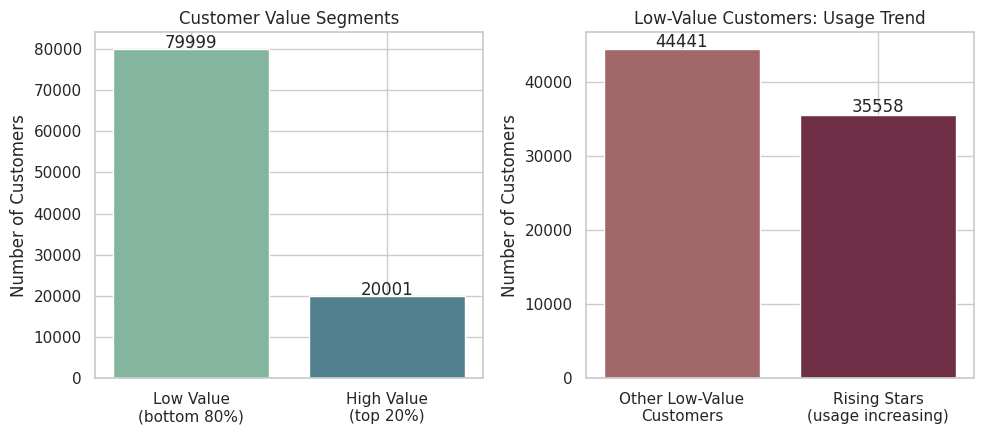

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10,4.5))

axes[0].bar(['Low Value\n(bottom 80%)','High Value\n(top 20%)'],
            [n_low_value, n_high_value], color=['#84B59F','#50808E'])
axes[0].set_title('Customer Value Segments')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate([n_low_value, n_high_value]):
    axes[0].text(i, v+300, str(v), ha='center')

values = [n_low_value - n_rising, n_rising]
axes[1].bar(['Other Low-Value\nCustomers', 'Rising Stars\n(usage increasing)'],
            values, color=['#A26769','#6D2E46'])
axes[1].set_title('Low-Value Customers: Usage Trend')
axes[1].set_ylabel('Number of Customers')
for i, v in enumerate(values):
    axes[1].text(i, v+300, str(v), ha='center')

plt.tight_layout()
plt.savefig('value_segments.png', dpi=100)
plt.show()

## 7. Quantified Business Impact

**Assumptions:**
- A "Rising Star" customer converted to high-value tier would earn the average revenue of
  current high-value customers (`avgrev` for `high_value==1`).
- We model three conversion-rate scenarios (5%, 10%, 20%) reflecting different levels of program
  succes.
- Industry estimates put new-customer acquisition cost at roughly 6-7x the cost of retaining
  an existing one (see References in the slides). This supports a retention/upsell-led strategy
  over new acquisition.

In [25]:
rising_stars_df = df[df['rising_star'] == 1]

avg_current_rev_rising = rising_stars_df['avgrev'].mean()
avg_high_value_rev = df[df['high_value']==1]['avgrev'].mean()
revenue_gap = avg_high_value_rev - avg_current_rev_rising

print(f'Rising Stars - current avg monthly revenue: ${avg_current_rev_rising:.2f}')
print(f'High-Value tier - avg monthly revenue:       ${avg_high_value_rev:.2f}')
print(f'Revenue gap per converted customer:          ${revenue_gap:.2f}')
print()

for conv_rate in [0.05, 0.10, 0.20]:
    n_converted = n_rising * conv_rate
    monthly_gain = n_converted * revenue_gap
    annual_gain = monthly_gain * 12
    print(f'At {conv_rate*100:.0f}% conversion ({n_converted:.0f} customers):')
    print(f'  +${monthly_gain:,.0f}/month  |  +${annual_gain:,.0f}/year')

Rising Stars - current avg monthly revenue: $44.32
High-Value tier - avg monthly revenue:       $112.22
Revenue gap per converted customer:          $67.90

At 5% conversion (1778 customers):
  +$120,717/month  |  +$1,448,605/year
At 10% conversion (3556 customers):
  +$241,434/month  |  +$2,897,209/year
At 20% conversion (7112 customers):
  +$482,868/month  |  +$5,794,418/year


### 7.1 Second Revenue Stream — High-Value Churn Reduction



**Assumptions:**


*   "Reduce churn by X%" means we save X% of the customers who would have left
*  Saved customers keep paying what they currently pay on average.



In [26]:
# High-Value Churn Reduction calculation
high_value_df = df[df['high_value'] == 1]

n_high_value_total = len(high_value_df)
churn_rate_hv = high_value_df['churn'].mean()
avg_rev_hv = high_value_df['avgrev'].mean()

n_churning_hv = n_high_value_total * churn_rate_hv

print(f'High-value customers:              {n_high_value_total:,}')
print(f'High-value churn rate:             {churn_rate_hv*100:.1f}%')
print(f'High-value avg monthly revenue:    ${avg_rev_hv:.2f}')
print(f'Estimated high-value customers\n  currently churning:               {n_churning_hv:.0f}')
print()

for reduction_pct in [0.05, 0.10, 0.15]:
    customers_retained = n_churning_hv * reduction_pct
    monthly_saved = customers_retained * avg_rev_hv
    annual_saved = monthly_saved * 12
    print(f'Reduce churn by {reduction_pct*100:.0f}%: retain {customers_retained:.0f} customers')
    print(f'  Monthly revenue saved: ${monthly_saved:,.0f}')
    print(f'  Annual revenue saved:  ${annual_saved:,.0f}')
    print()

High-value customers:              20,001
High-value churn rate:             48.3%
High-value avg monthly revenue:    $112.22
Estimated high-value customers
  currently churning:               9669

Reduce churn by 5%: retain 483 customers
  Monthly revenue saved: $54,252
  Annual revenue saved:  $651,019

Reduce churn by 10%: retain 967 customers
  Monthly revenue saved: $108,503
  Annual revenue saved:  $1,302,039

Reduce churn by 15%: retain 1450 customers
  Monthly revenue saved: $162,755
  Annual revenue saved:  $1,953,058




### 7.2 Combined Business Impact

Combining both independent revenue streams gives the total quantified opportunity from
deploying this model:

In [27]:
# Combined impact - base case (10% scenarios for both streams)
rising_stars_gain_base = n_rising * 0.10 * revenue_gap * 12
churn_reduction_gain_base = (n_high_value_total * churn_rate_hv * 0.10) * avg_rev_hv * 12

total_base_case = rising_stars_gain_base + churn_reduction_gain_base

print('BASE CASE COMBINED IMPACT (10% scenarios):')
print(f'  Rising Stars Upsell (10% conversion):     ${rising_stars_gain_base:,.0f}/year')
print(f'  High-Value Churn Reduction (10%):         ${churn_reduction_gain_base:,.0f}/year')
print(f'  {"-"*55}')
print(f'  TOTAL ANNUAL OPPORTUNITY:                 ${total_base_case:,.0f}/year')

BASE CASE COMBINED IMPACT (10% scenarios):
  Rising Stars Upsell (10% conversion):     $2,897,209/year
  High-Value Churn Reduction (10%):         $1,302,039/year
  -------------------------------------------------------
  TOTAL ANNUAL OPPORTUNITY:                 $4,199,248/year


## 8. Proposal Verification



### 8.1 Checking if the model actually rates rising stars higher

rising_star (the binary flag) was excluded from training, but change_mou itself was still in X

In [28]:
X_all_s = scaler.transform(X)
df['model_prob'] = best_lr.predict_proba(X_all_s)[:,1]

prob_hv = df.loc[df['high_value']==1, 'model_prob'].mean()
prob_rising = df.loc[df['rising_star']==1, 'model_prob'].mean()
prob_stagnant = df.loc[(df['high_value']==0) & (df['rising_star']==0), 'model_prob'].mean()

print(f'Avg model prob - High Value:        {prob_hv:.3f}')
print(f'Avg model prob - Rising Stars:       {prob_rising:.3f}')
print(f'Avg model prob - Stagnant Low-Value: {prob_stagnant:.3f}')

Avg model prob - High Value:        0.666
Avg model prob - Rising Stars:       0.082
Avg model prob - Stagnant Low-Value: 0.085


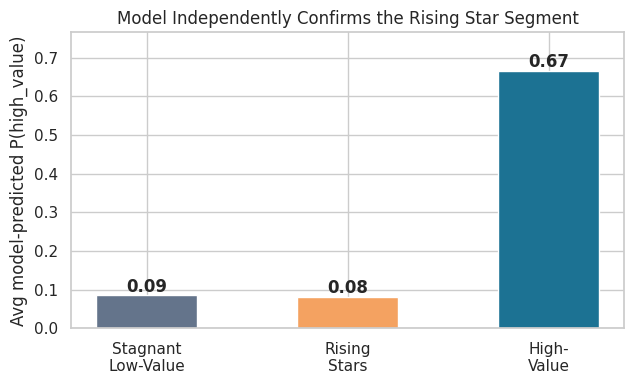

In [29]:
fig, ax = plt.subplots(figsize=(6.5,4))
segs = ['Stagnant\nLow-Value', 'Rising\nStars', 'High-\nValue']
vals = [prob_stagnant, prob_rising, prob_hv]
bars = ax.bar(segs, vals, color=['#64748B','#F4A261','#1C7293'], width=0.5)
for b,v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.01, f'{v:.2f}', ha='center', fontweight='bold')
ax.set_ylabel('Avg model-predicted P(high_value)')
ax.set_title('Model Independently Confirms the Rising Star Segment')
ax.set_ylim(0, max(vals)+0.1)
plt.tight_layout()
plt.savefig('verify_rising_star_prob.png', dpi=120, bbox_inches='tight')
plt.show()

### 8.2 Checking if rising stars actually grow revenu

change_rev was dropped since leakage

In [30]:
rev_growth_rising = df.loc[df['rising_star']==1, 'change_rev'].mean()
rev_growth_stagnant = df.loc[(df['high_value']==0) & (df['rising_star']==0), 'change_rev'].mean()

print(f'Avg monthly revenue change - Rising Stars:       ${rev_growth_rising:.2f}')
print(f'Avg monthly revenue change - Stagnant Low-Value: ${rev_growth_stagnant:.2f}')

Avg monthly revenue change - Rising Stars:       $10.12
Avg monthly revenue change - Stagnant Low-Value: $-6.50


### 8.3 Figuring out which stream should get priority

Comparing the two proposal streams on a per-customer basis, not just total $/year, to decide which one is the safer bet if budget/resources are limited.

In [31]:
upsell_per_customer = revenue_gap * 0.10 * 12
churn_per_customer = avg_rev_hv * churn_rate_hv * 0.10 * 12

print(f'Rising Stars  - expected gain per targeted customer: ${upsell_per_customer:,.2f}/yr')
print(f'Churn Reduction - expected gain per targeted customer: ${churn_per_customer:,.2f}/yr')
print()
print(f'Model confidence gap (Rising Star vs Stagnant): {prob_rising - prob_stagnant:.3f}')
print(f'Rising Star pool size: {n_rising:,} vs High-Value-at-risk pool: {int(n_high_value_total*churn_rate_hv):,}')

Rising Stars  - expected gain per targeted customer: $81.48/yr
Churn Reduction - expected gain per targeted customer: $65.10/yr

Model confidence gap (Rising Star vs Stagnant): -0.003
Rising Star pool size: 35,558 vs High-Value-at-risk pool: 9,669
